# ReservoirScope – IND320 Compulsory Assignment Part 2

This notebook documents the second part of the ReservoirScope project.

The work in this part focuses on:

- retrieving reservoir data directly from the NVE Magasinstatistikk API,
- replacing the local CSV workflow from Part 1,
- retrieving Norwegian cross-border transfer data from the ENTSO-E API,
- storing ENTSO-E data in Cassandra using Spark,
- extracting relevant data from Cassandra using Spark,
- transferring prepared data to MongoDB,
- and updating the Streamlit application to use API and database connections.

In [1]:
# Import libraries for data handling, API requests, and visualisation.
import pandas as pd
import requests
import matplotlib.pyplot as plt

## NVE Magasinstatistikk API

The local `reservoirs.csv` file used in Part 1 is replaced with a direct API connection.

The NVE Magasinstatistikk API provides reservoir statistics for different geographical area types in Norway.

The first step is to inspect the API response and identify the available fields, area types, and date variables before recreating the Part 1 analysis.

In [2]:
# NVE Magasinstatistikk API endpoint
nve_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Send GET request
response = requests.get(nve_url)

# Check whether request was successful
print("Status code:", response.status_code)

Status code: 200


In [3]:
# Convert API response from JSON to Python object
nve_data = response.json()

# Check the type and number of records
print(type(nve_data))
print("Number of records:", len(nve_data))

<class 'list'>
Number of records: 14931


In [4]:
# Convert API data to a Pandas DataFrame
reservior_df = pd.DataFrame(nve_data)

reservior_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [5]:
reservior_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14931 entries, 0 to 14930
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   14931 non-null  str    
 1   omrType                   14931 non-null  str    
 2   omrnr                     14931 non-null  int64  
 3   iso_aar                   14931 non-null  int64  
 4   iso_uke                   14931 non-null  int64  
 5   fyllingsgrad              14931 non-null  float64
 6   kapasitet_TWh             14931 non-null  float64
 7   fylling_TWh               14931 non-null  float64
 8   neste_Publiseringsdato    14931 non-null  str    
 9   fyllingsgrad_forrige_uke  14931 non-null  float64
 10  endring_fyllingsgrad      14931 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB


In [6]:
# Rename the original Norwegian NVE column names to clear English names
# that are used consistently throughout the notebook and Streamlit app.
reservior_df = reservior_df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_fill_level",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# Preview the renamed dataset.
reservior_df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,previous_week_fill_level,change_in_fill_level
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [7]:
# Convert date columns to datetime format
reservior_df["date"] = pd.to_datetime(
    reservior_df["date"],
    errors="coerce"
)

# Replace placeholder publication dates with missing values
reservior_df["next_publication_date"] = (
    reservior_df["next_publication_date"]
    .replace("0001-01-01T00:00:00", pd.NA)
)

reservior_df["next_publication_date"] = pd.to_datetime(
    reservior_df["next_publication_date"],
    errors="coerce"
)

reservior_df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,previous_week_fill_level,change_in_fill_level
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,NaT,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25 13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,NaT,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,NaT,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,NaT,0.311122,-0.010301


In [8]:
print("First date:", reservior_df["date"].min())
print("Last date:", reservior_df["date"].max())
print("Number of rows:", len(reservior_df))

First date: 1995-01-08 00:00:00
Last date: 2026-10-18 00:00:00
Number of rows: 14931


In [9]:
print("Area types:")
print(reservior_df["area_type"].value_counts())

Area types:
area_type
EL      8295
VASS    4977
NO      1659
Name: count, dtype: int64


In [10]:
# Identify the area numbers associated with each NVE area type
# so the geographical structure of EL, NO, and VASS can be inspected.
for area_type in reservior_df["area_type"].dropna().unique():
    area_numbers = sorted(
        reservior_df.loc[
            reservior_df["area_type"] == area_type,
            "area_number"
        ].unique()
    )

    print(area_type, ":", area_numbers)

EL : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
NO : [np.int64(0)]
VASS : [np.int64(1), np.int64(2), np.int64(3)]


In [11]:
# Check the number of missing values in each column
# to identify variables that may require additional preprocessing.
reservior_df.isna().sum()

date                            0
area_type                       0
area_number                     0
year                            0
week                            0
fill_level                      0
capacity_TWh                    0
stored_energy_TWh               0
next_publication_date       11322
previous_week_fill_level        0
change_in_fill_level            0
dtype: int64

## Exploratory Analysis of NVE Reservoir Data

The API data is explored to understand the geographical area types and the national reservoir observations before recreating the visualisations from Part 1.

In [12]:
# Filter national reservoir observations
national_df = reservior_df[
    (reservior_df["area_type"] == "NO") &
    (reservior_df["area_number"] == 0)
].copy()

national_df = national_df.sort_values("date")

national_df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,previous_week_fill_level,change_in_fill_level
9683,1995-01-08,NO,0,1995,1,0.607988,87.43758,53.161003,NaT,0.752631,-0.144643
9736,1995-01-15,NO,0,1995,2,0.582088,87.43758,50.896374,NaT,0.607988,-0.025900
9526,1995-01-22,NO,0,1995,3,0.562121,87.43758,49.150486,NaT,0.582088,-0.019967
9709,1995-01-29,NO,0,1995,4,0.534222,87.43758,46.711033,NaT,0.562121,-0.027899
9756,1995-02-05,NO,0,1995,5,0.506221,87.43758,44.262720,NaT,0.534222,-0.028001


In [13]:
# Summarise the national reservoir dataset by showing
# the number of observations and the available date range.
print("Number of national observations:", len(national_df))
print("First date:", national_df["date"].min())
print("Last date:", national_df["date"].max())

Number of national observations: 1659
First date: 1995-01-08 00:00:00
Last date: 2026-10-18 00:00:00


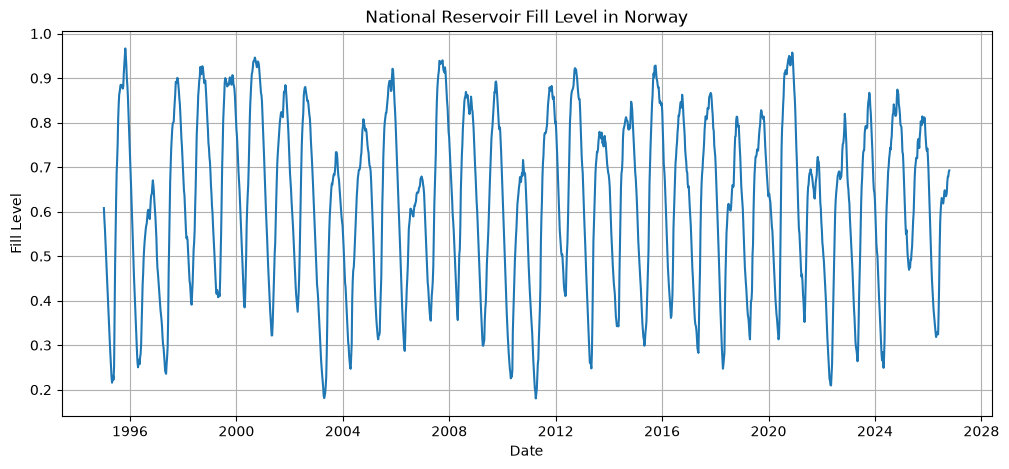

In [14]:
# Plot the national reservoir fill level over time
# to examine long-term changes in Norwegian reservoir storage.
plt.figure(figsize=(12, 5))

plt.plot(
    national_df["date"],
    national_df["fill_level"]
)

plt.title("National Reservoir Fill Level in Norway")
plt.xlabel("Date")
plt.ylabel("Fill Level")
plt.grid(True)

plt.show()

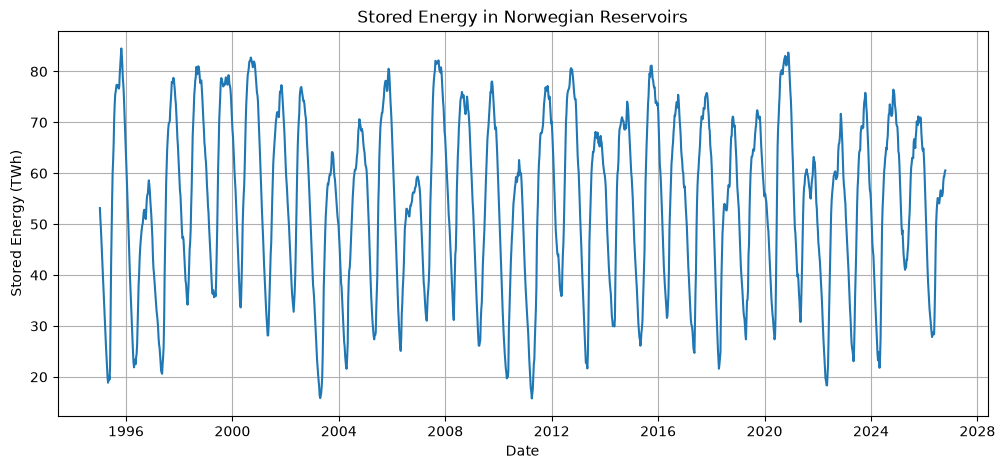

In [15]:
# Plot the stored energy in Norwegian reservoirs over time
# to examine how the total available reservoir energy changes.
plt.figure(figsize=(12, 5))

plt.plot(
    national_df["date"],
    national_df["stored_energy_TWh"]
)

plt.title("Stored Energy in Norwegian Reservoirs")
plt.xlabel("Date")
plt.ylabel("Stored Energy (TWh)")
plt.grid(True)

plt.show()

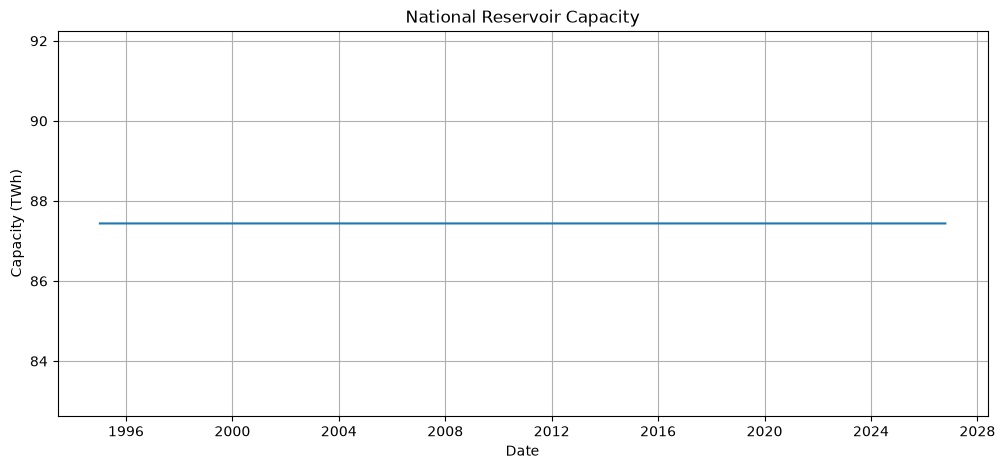

In [16]:
# Plot the total reservoir capacity in Norway over time
# to examine changes in the maximum available storage capacity.
plt.figure(figsize=(12, 5))

plt.plot(
    national_df["date"],
    national_df["capacity_TWh"]
)

plt.title("National Reservoir Capacity")
plt.xlabel("Date")
plt.ylabel("Capacity (TWh)")
plt.grid(True)

plt.show()

### Combined National Reservoir Measurements

The five main reservoir measurements have different units and numerical scales. To compare their development over time in one figure, each variable is normalized to a range from 0 to 1 using Min-Max normalization.

If a variable is constant across the selected period, it is assigned a normalized value of 0.5 to avoid division by zero.

In [17]:
# Select the five main measurement variables
measurement_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "previous_week_fill_level",
    "change_in_fill_level"
]

# Use date as index
national_measurements = national_df[
    ["date"] + measurement_columns
].copy()

national_measurements = national_measurements.set_index("date")

national_measurements.head()

,fill_level,capacity_TWh,stored_energy_TWh,previous_week_fill_level,change_in_fill_level
date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


In [18]:
# Min-Max normalization
column_min = national_measurements.min()
column_range = national_measurements.max() - column_min

normalized_data = (
    (national_measurements - column_min)
    / column_range.replace(0, float("nan"))
)

# Assign constant variables a value of 0.5
constant_columns = column_range[column_range == 0].index
normalized_data[constant_columns] = 0.5

normalized_data.head()

,fill_level,capacity_TWh,stored_energy_TWh,previous_week_fill_level,change_in_fill_level
date,,,,,
1995-01-08,0.543947,0.5,0.543947,0.727883,0.000000
1995-01-15,0.511010,0.5,0.511010,0.543941,0.439112
1995-01-22,0.485618,0.5,0.485618,0.511004,0.461051
1995-01-29,0.450139,0.5,0.450139,0.485612,0.431718
1995-02-05,0.414531,0.5,0.414531,0.450132,0.431343


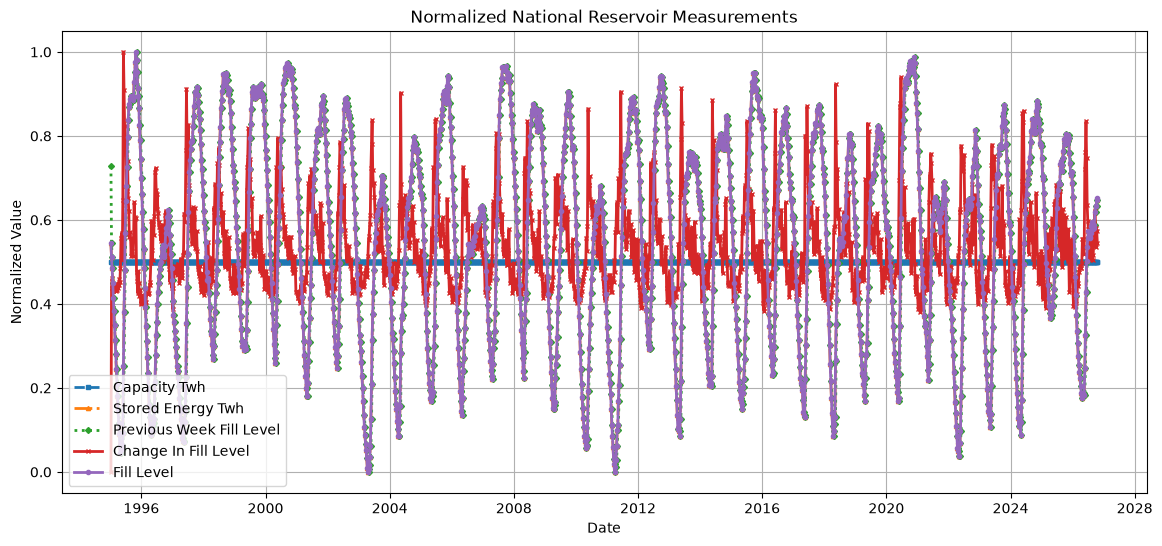

In [19]:
# Plot the normalized national reservoir measurements together
# so variables with different numerical scales can be compared
# within the same time-series visualisation.
plt.figure(figsize=(14, 6))

plot_order = [
    "capacity_TWh",
    "stored_energy_TWh",
    "previous_week_fill_level",
    "change_in_fill_level",
    "fill_level",
]

line_styles = {
    "capacity_TWh": "--",
    "stored_energy_TWh": "-.",
    "previous_week_fill_level": ":",
    "change_in_fill_level": "-",
    "fill_level": "-",
}

markers = {
    "capacity_TWh": "s",
    "stored_energy_TWh": "^",
    "previous_week_fill_level": "D",
    "change_in_fill_level": "x",
    "fill_level": "o",
}

for column in plot_order:
    plt.plot(
        normalized_data.index,
        normalized_data[column],
        label=column.replace("_", " ").title(),
        linestyle=line_styles[column],
        marker=markers[column],
        markersize=3,
        linewidth=2
    )

plt.title("Normalized National Reservoir Measurements")
plt.xlabel("Date")
plt.ylabel("Normalized Value")
plt.legend()
plt.grid(True)

plt.show()

In [20]:
# Display any variables that remained constant during the selected period
# and therefore required special handling during Min-Max normalisation.
print("Constant columns:", list(constant_columns))

Constant columns: ['capacity_TWh']


## ENTSO-E Cross-Border Physical Flow Data

The ENTSO-E Transparency Platform provides cross-border electricity
transmission data between European bidding zones.

For this project, cross-border physical flow data is retrieved for the
Norwegian NO2 bidding zone and the Netherlands for the last two years.

Both directions of each connection are collected so that electricity
flowing into Norway and electricity flowing out of Norway can be
analysed separately.

In [21]:
# Load the ENTSO-E API token securely from the local Streamlit secrets file
# so the credential is not hard-coded or exposed in the notebook.
import tomllib
from pathlib import Path

secrets_path = Path("../.streamlit/secrets.toml")

with open(secrets_path, "rb") as file:
    secrets = tomllib.load(file)

entsoe_token = secrets["ENTSOE_TOKEN"]

print("ENTSO-E token loaded successfully.")

ENTSO-E token loaded successfully.


In [22]:
# Create an ENTSO-E API client using the securely loaded token
# so cross-border electricity flow data can be requested from the platform.
import pandas as pd
from entsoe import EntsoePandasClient

client = EntsoePandasClient(
    api_key=entsoe_token
)

print("ENTSO-E client created.")

ENTSO-E client created.


In [23]:
# Define the cross-border connection used for the ENTSO-E analysis.
# The project focuses on electricity flow between Norway's NO2 zone
# and the Netherlands in both import and export directions.
connections = [
    ("NO_2", "NL")
]

In [24]:
# Define the two-year ENTSO-E analysis period using the Europe/Oslo timezone
# so timestamps are consistent with the Norwegian electricity market context.
start_date = pd.Timestamp(
    "2024-10-19",
    tz="Europe/Oslo"
)

end_date = pd.Timestamp(
    "2026-10-19",
    tz="Europe/Oslo"
)

print("Start:", start_date)
print("End:", end_date)

Start: 2024-10-19 00:00:00+02:00
End: 2026-10-19 00:00:00+02:00


### Downloading ENTSO-E Data

Cross-border physical flow data is retrieved in three-month chunks because
large requests to the ENTSO-E API can take a long time to complete.

The selected connection is Norway bidding zone NO2 and the Netherlands.
Both export and import directions are downloaded for the two-year period.

After retrieval, the data is stored in Cassandra and MongoDB so that
subsequent analysis can use the persisted database data without repeatedly
calling the ENTSO-E API.

In [25]:
# Download ENTSO-E cross-border electricity flow data in 3-month chunks
# to make the API requests more manageable over the two-year period.
# Both export from NO2 to the Netherlands and import in the opposite
# direction are retrieved and stored in a common list for later processing.
all_flows = []

for norway_zone, foreign_zone in connections:

    for from_zone, to_zone, direction in [
        (norway_zone, foreign_zone, "export"),
        (foreign_zone, norway_zone, "import"),
    ]:

        current_start = start_date

        while current_start < end_date:

            current_end = min(
                current_start + pd.DateOffset(months=3),
                end_date
            )

            print(
                f"{from_zone} -> {to_zone}: "
                f"{current_start.date()} to {current_end.date()}"
            )

            try:
                flow = client.query_crossborder_flows(
                    from_zone,
                    to_zone,
                    start=current_start,
                    end=current_end
                )

                if flow is not None and not flow.empty:

                    flow_df = (
                        flow
                        .rename("quantity_mw")
                        .reset_index()
                    )

                    flow_df.columns = [
                        "timestamp",
                        "quantity_mw"
                    ]

                    flow_df["from_zone"] = from_zone
                    flow_df["to_zone"] = to_zone
                    flow_df["direction"] = direction

                    all_flows.append(flow_df)

                    print("Rows:", len(flow_df))

            except Exception as error:
                print("ERROR:", error)

            current_start = current_end

NO_2 -> NL: 2024-10-19 to 2025-01-19
Rows: 8836
NO_2 -> NL: 2025-01-19 to 2025-04-19
Rows: 8636
NO_2 -> NL: 2025-04-19 to 2025-07-19
Rows: 8736
NO_2 -> NL: 2025-07-19 to 2025-10-19
Rows: 8832
NO_2 -> NL: 2025-10-19 to 2026-01-19
Rows: 8836
NO_2 -> NL: 2026-01-19 to 2026-04-19
Rows: 8636
NO_2 -> NL: 2026-04-19 to 2026-07-19
Rows: 8736
NO_2 -> NL: 2026-07-19 to 2026-10-19
Rows: 8832
NL -> NO_2: 2024-10-19 to 2025-01-19
Rows: 8836
NL -> NO_2: 2025-01-19 to 2025-04-19
Rows: 8636
NL -> NO_2: 2025-04-19 to 2025-07-19
Rows: 8736
NL -> NO_2: 2025-07-19 to 2025-10-19
Rows: 8832
NL -> NO_2: 2025-10-19 to 2026-01-19
Rows: 8836
NL -> NO_2: 2026-01-19 to 2026-04-19
Rows: 8636
NL -> NO_2: 2026-04-19 to 2026-07-19
Rows: 8736
NL -> NO_2: 2026-07-19 to 2026-10-19
Rows: 8832


In [26]:
print(
    "Successful datasets:",
    len(all_flows)
)

Successful datasets: 16


In [27]:
# Combine all downloaded ENTSO-E flow chunks into one DataFrame
# and verify the total number of rows and the balance between
# import and export observations.
entsoe_df = pd.concat(
    all_flows,
    ignore_index=True
)

print(
    "Total rows:",
    len(entsoe_df)
)

print(
    entsoe_df["direction"].value_counts()
)

Total rows: 140160
direction
export    70080
import    70080
Name: count, dtype: int64


In [28]:
# Convert ENTSO-E timestamps to timezone-aware UTC datetime values
# so the time data remains consistent during Spark and database processing.
entsoe_df["timestamp"] = pd.to_datetime(
    entsoe_df["timestamp"],
    utc=True
)

# Confirm the timestamp datatype and preview the prepared dataset.
print(entsoe_df["timestamp"].dtype)

entsoe_df.head()

datetime64[us, UTC]


,timestamp,quantity_mw,from_zone,to_zone,direction
0,2024-10-18 22:00:00+00:00,620.01,NO_2,NL,export
1,2024-10-18 22:15:00+00:00,620.01,NO_2,NL,export
2,2024-10-18 22:30:00+00:00,620.25,NO_2,NL,export
3,2024-10-18 22:45:00+00:00,620.49,NO_2,NL,export
4,2024-10-18 23:00:00+00:00,620.25,NO_2,NL,export


## Cassandra and Spark Pipeline

The ENTSO-E cross-border flow data is converted to a Spark DataFrame
and stored in Cassandra.

The stored data is then read back using Spark for further analysis.

In [29]:
# Create a Spark session configured with the Cassandra connector
# and use UTC as the Spark SQL timezone for consistent timestamp handling.
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("ReservoirScope_CA2")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config(
        "spark.cassandra.connection.host",
        "127.0.0.1"
    )
    .config(
        "spark.sql.session.timeZone",
        "UTC"
    )
    .getOrCreate()
)

# Reduce Spark console output and confirm the active configuration.
spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print(
    "Spark timezone:",
    spark.conf.get("spark.sql.session.timeZone")
)

26/10/27 07:27:35 WARN Utils: Your hostname, Jawarils-MacBook-Air.local resolves to a loopback address: 127.0.0.1; using 192.168.11.235 instead (on interface en0)
26/10/27 07:27:35 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/Users/twinkle/Desktop/NMBU/IND320/Project/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/twinkle/.ivy2/cache
The jars for the packages stored in: /Users/twinkle/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-73ae291e-5440-4182-b803-cd60b844bed5;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams

Spark version: 3.5.9
Spark timezone: UTC


In [30]:
# Convert the prepared ENTSO-E Pandas DataFrame into a Spark DataFrame
# containing only the fields needed for Cassandra storage and later analysis.
spark_df = spark.createDataFrame(
    entsoe_df[
        [
            "timestamp",
            "quantity_mw",
            "from_zone",
            "to_zone",
            "direction"
        ]
    ]
)

# Inspect the Spark schema and verify the number of import/export records.
spark_df.printSchema()

spark_df.groupBy(
    "direction"
).count().show()

root
 |-- timestamp: timestamp (nullable = true)
 |-- quantity_mw: double (nullable = true)
 |-- from_zone: string (nullable = true)
 |-- to_zone: string (nullable = true)
 |-- direction: string (nullable = true)



+---------+-----+
|direction|count|
+---------+-----+
|   export|70080|
|   import|70080|
+---------+-----+



In [31]:
# Remove duplicate records that would conflict with the Cassandra primary key.
# The Cassandra key is based on from_zone, to_zone, and timestamp,
# so only one record is kept for each unique cross-border observation.
spark_df = spark_df.dropDuplicates(
    [
        "from_zone",
        "to_zone",
        "timestamp"
    ]
)

# Confirm the number of rows remaining after deduplication.
print(
    "Rows after removing Cassandra-key duplicates:",
    spark_df.count()
)

Rows after removing Cassandra-key duplicates: 140144


A small number of records share the same Cassandra primary-key combination
of `from_zone`, `to_zone`, and `timestamp`. These records are removed before
writing to Cassandra so that the Spark dataset matches the Cassandra table
structure.

In [32]:
# Verify the number of import and export records before writing
# the deduplicated Spark DataFrame to Cassandra.
print("Before Cassandra:")
spark_df.groupBy("direction").count().show()

Before Cassandra:


+---------+-----+
|direction|count|
+---------+-----+
|   import|70072|
|   export|70072|
+---------+-----+



The Cassandra table was created before running this notebook with
`(from_zone, to_zone, timestamp)` as the primary key. Before refreshing
the full dataset, the existing table should be cleared to avoid retaining
records from earlier runs.

In [33]:
# Write the deduplicated ENTSO-E Spark DataFrame to the
# reservoirscope.entsoe_flows table in Cassandra.
spark_df.write \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="entsoe_flows",
        keyspace="reservoirscope"
    ) \
    .mode("append") \
    .save()

print("ENTSO-E data written to Cassandra.")

ENTSO-E data written to Cassandra.


In [34]:
# Read the stored ENTSO-E records back from Cassandra using Spark
# to confirm that the database connection and write operation worked.
cassandra_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        table="entsoe_flows",
        keyspace="reservoirscope"
    )
    .load()
)

# Confirm the total number of records retrieved from Cassandra.
print(
    "Rows read from Cassandra:",
    cassandra_df.count()
)

Rows read from Cassandra: 140144


In [35]:
# Select only the ENTSO-E fields needed for analysis
# and register the result as a temporary Spark SQL view.
selected_df = cassandra_df.select(
    "timestamp",
    "quantity_mw",
    "from_zone",
    "to_zone",
    "direction"
)

selected_df.createOrReplaceTempView(
    "crossborder_flows"
)

## Spark Extraction and Visualisation

Spark SQL is used to extract relevant cross-border flow data from
Cassandra for the required visualisations.

In [36]:
# Calculate the total imported and exported electricity energy for 2025
# on the NO2–Netherlands connection using Spark SQL.
# Because ENTSO-E values are recorded every 15 minutes,
# MW is multiplied by 0.25 hours to convert the totals to MWh.
pie_df = spark.sql("""
    SELECT
        direction,
        SUM(quantity_mw) * 0.25 AS total_mwh
    FROM crossborder_flows
    WHERE YEAR(timestamp) = 2025
      AND (
          (from_zone = 'NO_2' AND to_zone = 'NL')
          OR
          (from_zone = 'NL' AND to_zone = 'NO_2')
      )
    GROUP BY direction
""")

# Display the yearly import/export totals used for the pie chart.
pie_df.show()

+---------+------------------+
|direction|         total_mwh|
+---------+------------------+
|   export| 2791139.647500097|
|   import|415115.66750000144|
+---------+------------------+



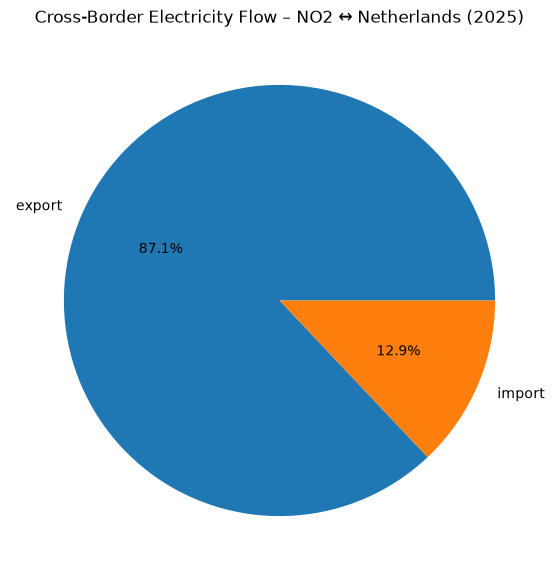

In [37]:
# Convert the Spark SQL result to Pandas and create a pie chart
# showing the proportion of imported and exported electricity energy
# for the NO2–Netherlands connection during 2025.
pie_pd = pie_df.toPandas()

plt.figure(figsize=(7, 7))

plt.pie(
    pie_pd["total_mwh"],
    labels=pie_pd["direction"],
    autopct="%1.1f%%"
)

plt.title(
    "Cross-Border Electricity Flow – NO2 ↔ Netherlands (2025)"
)

plt.show()

The pie chart compares the total electricity exchanged between Norway and
the Netherlands in 2025. Both import and export directions are represented,
making it possible to see which direction accounted for the larger share of
the yearly cross-border energy flow.
Because the ENTSO-E observations for this connection are reported at
15-minute intervals, each MW observation is multiplied by 0.25 hours
when calculating total energy in MWh.

In [38]:
# Extract January 2025 electricity flow data for the
# NO2–Netherlands connection using Spark SQL.
# Separate import and export records are retained for the line plot.
january_df = spark.sql("""
    SELECT
        timestamp,
        quantity_mw,
        direction
    FROM crossborder_flows
    WHERE YEAR(timestamp) = 2025
      AND MONTH(timestamp) = 1
      AND (
          (from_zone = 'NO_2' AND to_zone = 'NL')
          OR
          (from_zone = 'NL' AND to_zone = 'NO_2')
      )
    ORDER BY timestamp
""")

# Preview the first ten January observations.
january_df.show(10)

+-------------------+-----------+---------+
|          timestamp|quantity_mw|direction|
+-------------------+-----------+---------+
|2025-01-01 00:00:00|        0.0|   export|
|2025-01-01 00:00:00|     649.09|   import|
|2025-01-01 00:15:00|        0.0|   export|
|2025-01-01 00:15:00|     649.09|   import|
|2025-01-01 00:30:00|        0.0|   export|
|2025-01-01 00:30:00|     649.09|   import|
|2025-01-01 00:45:00|        0.0|   export|
|2025-01-01 00:45:00|     649.09|   import|
|2025-01-01 01:00:00|        0.0|   export|
|2025-01-01 01:00:00|     649.09|   import|
+-------------------+-----------+---------+
only showing top 10 rows



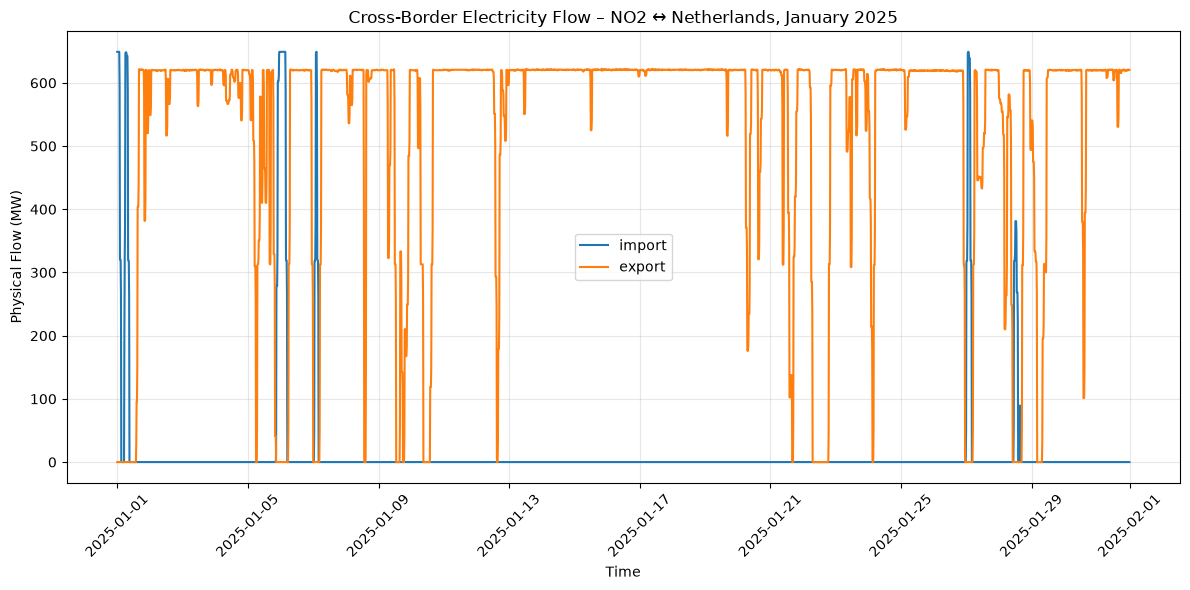

In [39]:
# Convert the January Spark result to Pandas and plot the
# cross-border physical electricity flow for each direction.
# Separate lines are used for import and export during January 2025.
january_pd = january_df.toPandas()

plt.figure(figsize=(12, 6))

for direction in january_pd["direction"].unique():

    direction_data = january_pd[
        january_pd["direction"] == direction
    ]

    plt.plot(
        direction_data["timestamp"],
        direction_data["quantity_mw"],
        label=direction
    )

plt.title(
    "Cross-Border Electricity Flow – NO2 ↔ Netherlands, January 2025"
)

plt.xlabel("Time")
plt.ylabel("Physical Flow (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

The line plot shows the physical electricity flow between Norway and the
Netherlands during January 2025.

Separate lines are used for imports and exports, making it possible to see
how the direction and magnitude of electricity flow changed throughout the
month.

## Transfer Curated Spark Data to MongoDB

The ENTSO-E data read from Cassandra using Spark is transferred to
MongoDB for use in the Streamlit application.

In [40]:
# Convert the curated Spark DataFrame to Pandas
# so the records can be prepared for insertion into MongoDB.
mongo_df = selected_df.toPandas()

# Preview the prepared MongoDB dataset.
mongo_df.head()

,timestamp,quantity_mw,from_zone,to_zone,direction
0,2024-10-18 22:00:00,0.0,NL,NO_2,import
1,2024-10-18 22:15:00,0.0,NL,NO_2,import
2,2024-10-18 22:30:00,0.0,NL,NO_2,import
3,2024-10-18 22:45:00,0.0,NL,NO_2,import
4,2024-10-18 23:00:00,0.0,NL,NO_2,import


In [41]:
# Load the MongoDB connection string securely from the local
# Streamlit secrets file so database credentials are not exposed.
import tomllib
from pathlib import Path
from pymongo import MongoClient

secrets_path = Path("../.streamlit/secrets.toml")

with open(secrets_path, "rb") as file:
    secrets = tomllib.load(file)

# Create the MongoDB client and test the connection.
client = MongoClient(
    secrets["MONGODB_URI"]
)

client.admin.command("ping")

print("MongoDB connection works.")

MongoDB connection works.


### Preparing the MongoDB Collection

Before inserting the final curated Spark dataset, the existing
`entsoe_flows` collection was cleared to prevent duplicate records.

This operation was performed before the final insertion. The final
MongoDB collection contains 140,144 documents.

In [43]:
# Select the ReservoirScope database and ENTSO-E collection
# that will store the curated electricity transmission records.
db = client["reservoirscope"]

collection = db["entsoe_flows"]

In [44]:
# Convert the prepared Pandas DataFrame into a list of records
# and insert the documents into MongoDB in batches to avoid
# sending one very large database request at once.
records = mongo_df.to_dict("records")

batch_size = 10000

for start in range(
    0,
    len(records),
    batch_size
):

    batch = records[
        start:start + batch_size
    ]

    collection.insert_many(batch)

# Confirm the final number of documents stored in MongoDB.
print(
    "Documents in MongoDB:",
    collection.count_documents({})
)

Documents in MongoDB: 280288


In [45]:
# Retrieve one document from the MongoDB collection
# to verify that the inserted ENTSO-E records are stored correctly.
collection.find_one()

{'_id': ObjectId('6add8958ef757528d8a67608'),
 'timestamp': datetime.datetime(2024, 10, 18, 22, 0),
 'quantity_mw': 620.01,
 'from_zone': 'NO_2',
 'to_zone': 'NL',
 'direction': 'export'}

## Project Links

- **GitHub Repository:** https://github.com/Zawaril/ReservoirScope
- **Streamlit Application:** https://reservoirscope.streamlit.app/

## Development Log

The second part of ReservoirScope extended the project from a local CSV-based analysis into a data pipeline using APIs, Spark, Cassandra, MongoDB, and Streamlit.

For the reservoir data, I replaced the CSV file used in Part 1 with a direct connection to the NVE Magasinstatistikk API. The API response contained the same main variables that were used previously, which made it possible to reuse much of the preprocessing and visualisation logic. The Norwegian column names were renamed to descriptive English names, date variables were converted to datetime format, and invalid placeholder publication dates were handled as missing values. I recreated the national reservoir visualisations and the normalized comparison of the main reservoir measurements.

The ENTSO-E part was more challenging. I first had to obtain REST API access and a security token. I used the `entsoe-py` package to retrieve cross-border physical electricity flow data. Large requests were slow, so I eventually downloaded the data in smaller time chunks. For the final analysis, I used the NO2–Netherlands connection and retrieved both import and export directions for a two-year period.

The ENTSO-E data was converted to a Spark DataFrame and stored in Cassandra. A small number of rows shared the same Cassandra primary-key combination, so duplicate keys were removed before storage. The data was then read back from Cassandra using Spark. Spark SQL was used to extract the relevant data for the required yearly pie chart and January line plot.

The curated Spark data was transferred to MongoDB Atlas, which acts as the remote database for the Streamlit application. The Streamlit application was updated to retrieve reservoir data directly from the NVE API and electricity transmission data from MongoDB. Interactive controls were added for area type, reservoir area number, year, month, and electricity connection.

Overall, the most time-consuming parts were configuring the different technologies and understanding the ENTSO-E data structure. Once the API and database connections were working, integrating the results into Streamlit was much more straightforward.

### NVE Download Interval

The NVE `HentOffentligData` endpoint used in this project returns the
complete public reservoir dataset and does not provide start and end
date parameters.

For this reason, the API response is retrieved and cached first. The
month-range control in the Streamlit application then determines which
interval of the retrieved API data is selected for analysis and
visualisation.

## Description of AI Usage

I used ChatGPT as a supporting tool throughout the development of this assignment.

The main uses of AI were interpreting the assignment requirements, debugging Python and PySpark errors, understanding the ENTSO-E and NVE API workflows, and configuring Cassandra, MongoDB, and Streamlit. ChatGPT also helped me understand error messages related to Spark, Cassandra primary keys, timestamp handling, and database connections.

AI assistance was also used when restructuring the Streamlit application, creating interactive controls, improving visualisations, and organizing the notebook documentation. Suggestions were reviewed, adapted, and tested before being included in the final project.

I also used ChatGPT to improve comments, explanations, and the development log. The final implementation, testing, and decisions about the project structure were carried out by me.

## Conclusion

ReservoirScope Part 2 extends the original reservoir analysis into a multi-source data pipeline.

Reservoir statistics are retrieved directly from the NVE Magasinstatistikk API, replacing the local CSV workflow from Part 1. Cross-border electricity flow data is retrieved from the ENTSO-E Transparency Platform, with the final analysis focusing on the NO2–Netherlands connection and comparing import and export flows over a two-year period.

Spark is used to process the ENTSO-E data, while Cassandra provides local database storage for the cross-border flow records. The processed data is then transferred to MongoDB Atlas, which serves as the remote data source for the Streamlit application.

The final project therefore combines API-based data retrieval, data preprocessing, Spark-based processing, local and remote database technologies, and interactive Streamlit visualisation in one complete workflow.